In [1]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

import optuna
import optuna.visualization as vis
from optuna.integration import XGBoostPruningCallback

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    KFold,
    TimeSeriesSplit,
    cross_val_score,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance

<h2>Read-in Data</h2>

In [2]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

In [ ]:
# Combine both operating and non-operating data into a full dataset for consistent time series analysis

# Data with operations
campd_tx_operating = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned.csv", dtype=campd_type_dict, date_format=["Date"])
# Data without operations
campd_tx_nonoperating = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_NonOperating.csv", dtype=campd_type_dict, date_format=["Date"])

campd_tx = pd.concat([campd_tx_operating, campd_tx_nonoperating])
del campd_tx_nonoperating
del campd_tx_operating
gc.collect()

# create full datetime column (date + hour)
campd_tx["datetime"] = pd.to_datetime(campd_tx["Date"].astype(str) + ' ' + campd_tx["Hour"].astype(str).str.zfill(2) + ":00:00")

campd_tx.to_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_Full.csv", index=False)

In [6]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_tx["Date"] = pd.to_datetime(campd_tx["Date"])
campd_tx["datetime"] = pd.to_datetime(campd_tx["datetime"])

<h2>Regression Models</h2>

<h3>Random Forest</h3>

<h3>XGBoost</h3>

<h5>Preprocessing Methods</h5>

In [2]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # Combine the two dfs
    df = pd.concat([df, previous_year_df])

    # Set datetime as the index for time-series operations
    df = df.set_index("datetime")

    # Sort the DataFrame by the datetime index to ensure proper alignment
    df = df.sort_index()

    # Sort the DataFrame by Facility ID, Unit ID, and datetime to ensure proper alignment
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # Apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # Filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime(df["Date"].astype(str) + ' ' + df["Hour"].astype(str).str.zfill(2) + ":00:00")


    return df


In [3]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_tx, tx_code_cols = preprocess_program_codes(campd_tx)
# tx_code_cols

<h5>Full Model Train and Test</h5>

<h6>Preprocessing</h6>

In [7]:
campd_tx["Day"] = campd_tx["datetime"].dt.day

In [ ]:
# read in previous year to get according lags
campd_tx_2018 = pd.read_csv("TX/Hourly/Before 2019/emissions-hourly-2018-tx.csv", dtype=campd_type_dict, date_format=["Date"])
campd_tx_2018 = campd_tx_2018[["Facility ID", "Unit ID", "Date", "Hour", "CO2 Mass (short tons)"]]
campd_tx_2018["datetime"] = pd.to_datetime(campd_tx_2018["Date"].astype(str) + ' ' + campd_tx_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_tx_2018["CO2 Mass (short tons)"] = campd_tx_2018["CO2 Mass (short tons)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_tx, campd_tx_2018, "CO2 Mass (short tons)")

In [9]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [10]:
# manually one-hot encode program codes
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [11]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [12]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [13]:
campd_df.shape

(20486426, 73)

In [14]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [15]:
campd_df.shape

(10384735, 73)

In [16]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", dtype=campd_type_dict)

In [17]:
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured                   8767620
Nothing                    1122410
Measured and Substitute     352561
Other                        87856
LME                          43060
Substitute                   11228
Name: count, dtype: Int64

In [18]:
campd_df = campd_df[(campd_df["CO2 Mass Measure Indicator"] == "Measured") | (campd_df["CO2 Mass Measure Indicator"] == "Nothing")]
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured    8767620
Nothing     1122410
Name: count, dtype: Int64

In [19]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", index=False)

In [3]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [4]:
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [5]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                #'unit_age_min',
                #'unit_age_max', 
                #'unit_age_mean', # removed gen ages because it likely works as a proxy for facility/unit id rather than causal age effects
                 'Year']

unencoded_cat_features = [#'Month', 'Hour', #'Day',  # manually encode with sin/cos 
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) + cyclical_cols + lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Source Category', 'Unit Type',
                                  'Primary Fuel Type', 'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_factor',
                                  'Summer Capacity (MW)',
                                  'Winter Capacity (MW)', 'Minimum Load (MW)',
                                  'Year']),
                                ('encoded', 'passthrough',
                                 ['ARP', 'CSOSG2', 'MATS', 'Missing', 'TXSO2',
                                  'Hour_sin', 'Hour_cos', 'Day_sin', 'Day_cos',
                                  'Month_sin', 'Month_cos', 'lag_1_hour',
                                  'lag_2_hours', 'lag_1_day', 'lag_2_days',
                                  'lag_1_week', 'lag_1_month', 'lag_1_year'])])

In [6]:
X_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_train", index=False)
X_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_test", index=False)
y_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/y_train", index=False)
y_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/y_test", index=False)

In [ ]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_train", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_test", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/y_train")
y_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/y_test")

In [7]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [8]:
X_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed", index=False)
X_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed", index=False)

In [64]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed", dtype=campd_type_dict)

In [9]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [10]:
dtrain.save_binary("TX/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_tx_full_2019_2023.buffer")
dtest.save_binary("TX/Hourly/Concatted File/Modeling/XGB/CO2/dtest_tx_full_2024.buffer")

In [ ]:
dtrain = xgb.DMatrix("TX/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_tx_full_2019_2023.buffer")
dtest = xgb.DMatrix("TX/Hourly/Concatted File/Modeling/XGB/CO2/dtest_tx_full_2024.buffer")

<h6>Using Default Parameters</h6>

In [11]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "tree_method": "hist", # approximation (faster, but not exact, should change on final run)
    #"device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [37]:
# Time Series Split

n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)
best_iterations = []
rmse_scores = []
r2_scores = []

# iterate over each fold and assign the train and test values based on the indeces of the TimeSeriesSplit
for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
    current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
    current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]
    
    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)
    
    # train a model on the current training data and validate it on testing data. create models with up to 1000 boost round until validation shows no more progress (after 20 rounds)
    model = xgb.train(
        default_params,
        current_dtrain,
        num_boost_round=1000,
        early_stopping_rounds=20,
        evals=[(current_dtest, "validation")],
        verbose_eval=False # prevents printing at each boosting stage
    )
    
    # predict on validation for this fold and store the evaluation metric rmse
    y_pred = model.predict(current_dtest)
    rmse = root_mean_squared_error(current_y_test, y_pred)
    r2 = r2_score(current_y_test, y_pred)
    
    best_iterations.append(model.best_iteration)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    
    print(f"Fold {fold+1}: best_iteration={model.best_iteration}, RMSE={rmse:.4f}, R2={r2:.4f}")

# average best iteration across all folds
optimal_rounds = int(np.mean(best_iterations))
print(f"\nOptimal num_boost_round (avg): {optimal_rounds}")
print(f"Average RMSE across folds: {np.mean(rmse_scores):.4f}")
print(f"Average R2 across folds: {np.mean(r2_scores):.4f}")


Fold 1: best_iteration=200, RMSE=4.1580, R2=0.9993
Fold 2: best_iteration=24, RMSE=4.3843, R2=0.9994
Fold 3: best_iteration=286, RMSE=3.9518, R2=0.9995
Fold 4: best_iteration=576, RMSE=2.8001, R2=0.9997
Fold 5: best_iteration=520, RMSE=2.7310, R2=0.9997

Optimal num_boost_round (avg): 321
Average RMSE across folds: 3.6050
Average R2 across folds: 0.9995


R^2 Score: 0.9986
Mean Squared Error (MSE): 26.3463
Root Mean Squared Error (RMSE): 5.1329


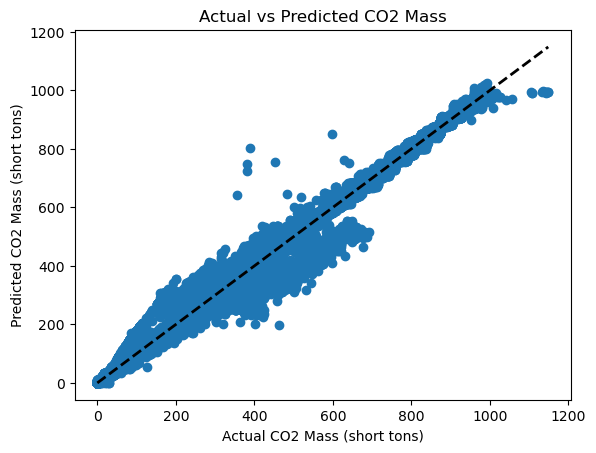

In [45]:
# model with default parameters (no lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

R^2 Score: 0.9995
Mean Squared Error (MSE): 9.7561
Root Mean Squared Error (RMSE): 3.1235


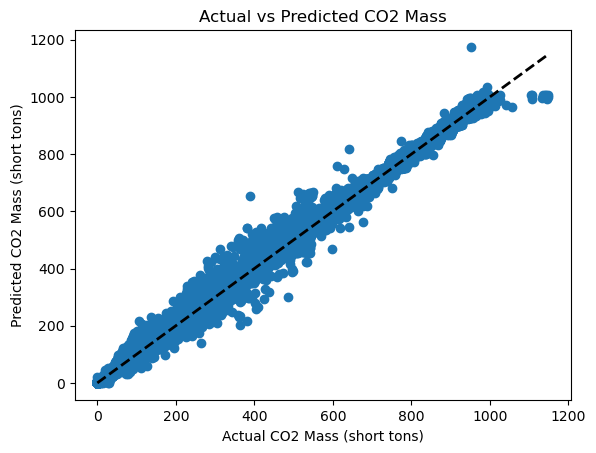

In [12]:
# model with default parameters (with lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_tx_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

In [ ]:
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for CO2 Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for CO2 Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for NOx Mass below 500 lbs: 7.3223
RMSE for NOx Mass above 500 lbs: 101.5071


<h6>HPO - Optuna Trials</h6>

In [ ]:
# default parameters for comparison
# optimization has bias variance tradeoff, see documentation: https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html

default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "tree_method": "hist", # approximation (faster, but not exact, should change on final run)
    "device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [ ]:
# objective function for optuna
def objective(trial):
    print(f"Starting trial {trial.number}")

    params = {
        "max_depth": trial.suggest_int("max_depth", 4, 25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.25),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 0.2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 6.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "tree_method": "hist",
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        #"device": "cuda"  # or "cpu"
    }

    tscv = TimeSeriesSplit(n_splits=5)
    rmse_folds = []
    best_iterations = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
        current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
        current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]

        current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
        current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

        evals_result = {}
        model = xgb.train(
            params,
            current_dtrain,
            num_boost_round=1000,
            evals=[(current_dtest, "validation")],
            early_stopping_rounds=20,
            verbose_eval=False, # prevents printing at each boosting stage
            evals_result=evals_result
        )

        best_iterations.append(model.best_iteration)
        # Get last RMSE from evals_result
        fold_rmse = evals_result["validation"]["rmse"][model.best_iteration - 1] # (0-indexed)
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold+1} rmse: {fold_rmse:.4f} best_iteration: {model.best_iteration}")

    avg_rmse = np.mean(rmse_folds)
    avg_best_iter = int(np.mean(best_iterations))

    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}, avg best_iteration: {avg_best_iter}")

    # manually store the avg best boosting rounds and full list of rmse folds (we output the avg rmse separately)
    trial.set_user_attr("best_iteration", avg_best_iter)
    trial.set_user_attr("fold_rmses", rmse_folds)

    return avg_rmse


In [ ]:
study = optuna.create_study(study_name="HPT 22.06.25 18:04", storage="sqlite:///optuna_studies.db", direction="minimize")
study.optimize(objective, n_trials=50) 
print("Best params:", study.best_params)

In [ ]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

# Get the best 5 trials
sorted_trials = sorted(
    [t for t in study.trials if t.value is not None], 
    key=lambda t: t.value
)

for i, trial in enumerate(sorted_trials[:5], 1):
    print(f"\nTrial {i}:")
    print(f"  Value (Objective): {trial.value}")
    print(f"  Number: {trial.number}")
    print(f"  Params:")
    for key, val in trial.params.items():
        print(f"    {key}: {val}")
    print(f"best_iteration: {trial.user_attrs.get("best_iteration")}")

second_best_params = sorted_trials[1]



Trial 1:
  Value (Objective): 9.745089838254874
  Number: 43
  Params:
    max_depth: 14
    learning_rate: 0.01070681077554956
    subsample: 0.318354394879375
    colsample_bytree: 0.777646548524244
    gamma: 0.3607772120989284
    reg_alpha: 0.0108703758177803
    reg_lambda: 0.38740560311398076
    min_child_weight: 7
best_iteration: 570

Trial 2:
  Value (Objective): 9.764771259078591
  Number: 36
  Params:
    max_depth: 14
    learning_rate: 0.028307079329367588
    subsample: 0.5346591526735095
    colsample_bytree: 0.755707012641865
    gamma: 0.32794467494879476
    reg_alpha: 0.03674279467914575
    reg_lambda: 1.067013332785789
    min_child_weight: 15
best_iteration: 243

Trial 3:
  Value (Objective): 9.767127299776904
  Number: 51
  Params:
    max_depth: 14
    learning_rate: 0.010448475834795221
    subsample: 0.47530695004986934
    colsample_bytree: 0.7956950970651904
    gamma: 0.3060105397027625
    reg_alpha: 0.020536194292598522
    reg_lambda: 0.105707880825134

In [23]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

# HPO visualizations
fig1 = vis.plot_param_importances(study)
fig2 = vis.plot_optimization_history(study)
fig3 = vis.plot_slice(study)

# update font to Times New Roman
for fig in [fig1, fig2, fig3]:
    fig.update_layout(font=dict(family="Times New Roman", size=14)) 
    fig.show()

Best params: {'max_depth': 14, 'learning_rate': 0.01070681077554956, 'subsample': 0.318354394879375, 'colsample_bytree': 0.777646548524244, 'gamma': 0.3607772120989284, 'reg_alpha': 0.0108703758177803, 'reg_lambda': 0.38740560311398076, 'min_child_weight': 7}
Best value (RMSE): 9.745089838254874
570


<h6>HPO - Model</h6>

In [36]:
# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}

In [ ]:
# second best params found
second_best_hpo_params = {
    **second_best_params.params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}


In [ ]:
default_params = {
    "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    "tree_method": "auto" # automatically chooses exact or approximation method based on data size
}

R^2 Score: 0.9833
Mean Squared Error (MSE): 61.3581
Root Mean Squared Error (RMSE): 7.8331


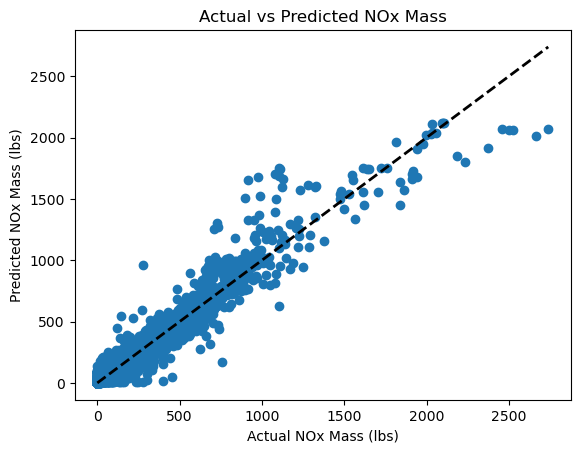

In [ ]:
# model with second best (less boost rounds) hpo parameters (with lags, no unmeasured data)

xgb_hpo_model = xgb.train(params=second_best_hpo_params, dtrain=dtrain, num_boost_round=254)

# dump model
xgb_hpo_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_hpo_model_tx_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

R^2 Score: 0.9834
Mean Squared Error (MSE): 60.9311
Root Mean Squared Error (RMSE): 7.8058


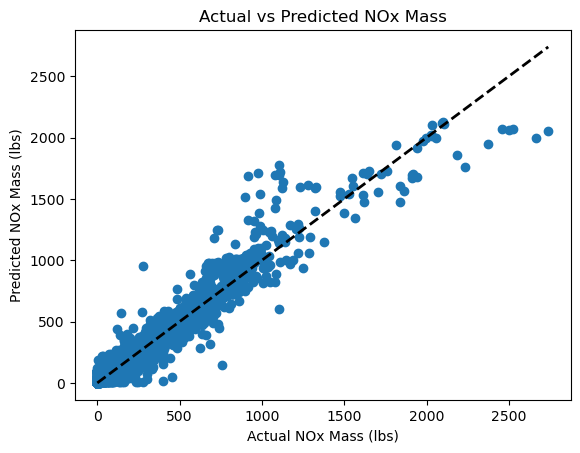

In [ ]:
# model with best hpo parameters (no unmeasured data)

xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=570)

# dump model
#xgb_hpo_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained/Models/xgb_hpo_model_tx_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [ ]:
# load saved models
xgb_default_model = xgb.Booster()
xgb_default_model.load_model("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_tx_with_lags_no_unmeasured.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured.json")

xgb_hpo_model = xgb.Booster()
xgb_hpo_model.load_model("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_hpo_model_tx_with_lags_no_unmeasured.json")


<h3>XGB (model-specific)</h3>

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

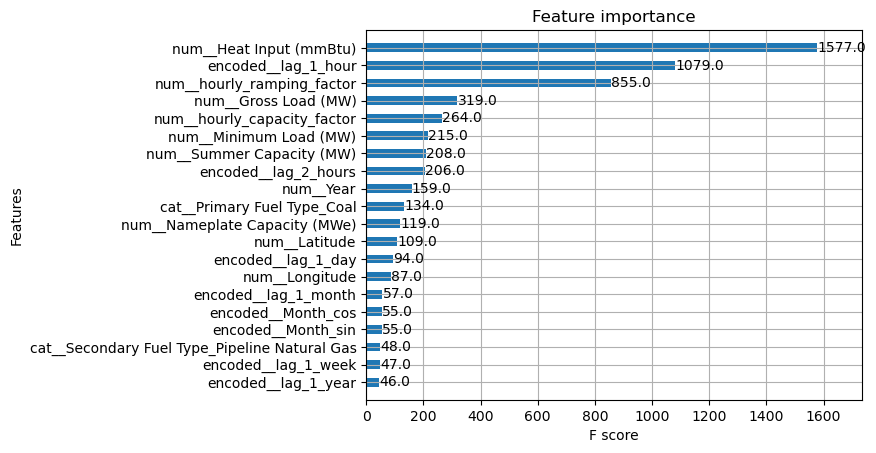

In [48]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

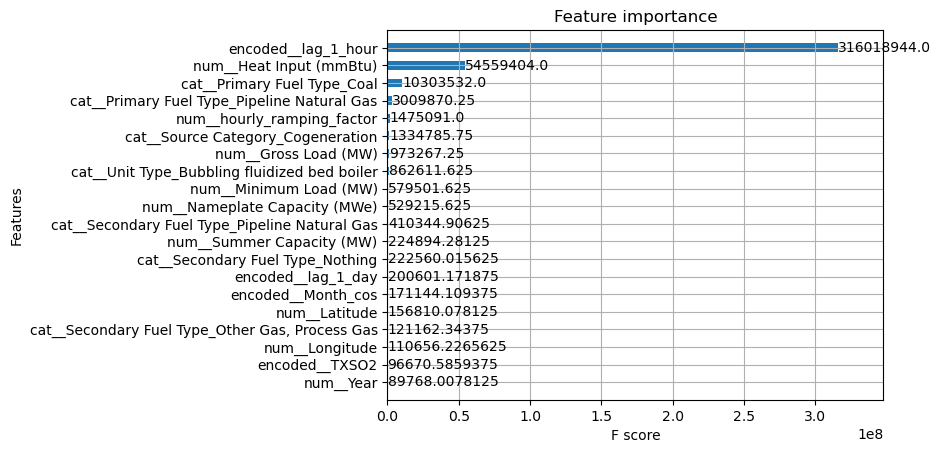

In [49]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

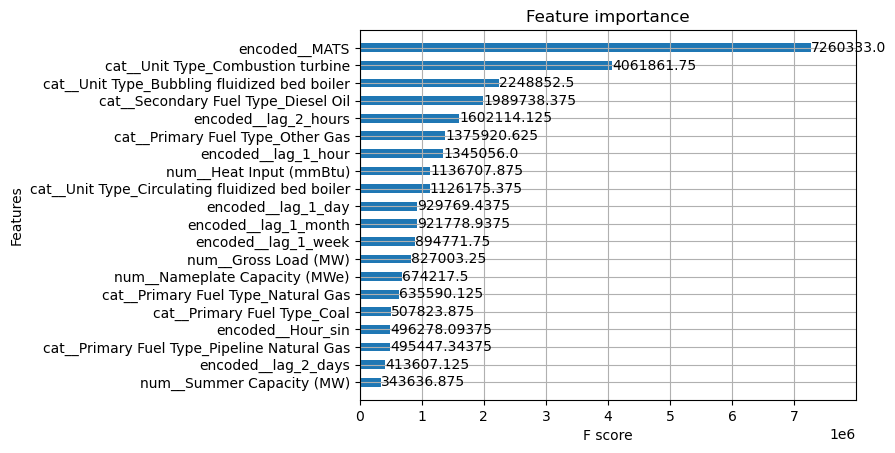

In [50]:
# use cover for feature importance (how matx observations are affected by the feature)
plot_importance(
    xgb_default_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h5>HPO Params</h5>

In [ ]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_hpo_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use cover for feature importance (how matx observations are affected by the feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Partial Dependence Plots</h3>

<h3>Permutation Importance</h3>

<h4>Default Params</h4>

In [ ]:
xgb_default_model = xgb.Booster()
xgb_default_model.load_model("xgb_default_model_tx.json")

In [22]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model

In [ ]:
y_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/y_test")


In [ ]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


<h4>Ungrouped</h4>

In [ ]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


In [26]:
# num features
num_features = ['num__Gross Load (MW)',
                 'num__Heat Input (mmBtu)', 
                 'num__Latitude', 
                 'num__Longitude', 
                 'num__Nameplate Capacity (MWe)',
                   'num__hourly_capacity_factor', 
                   'num__hourly_ramping_factor', 
                   'num__Summer Capacity (MW)', 
                   'num__Winter Capacity (MW)', 
                   'num__Minimum Load (MW)'] # we ignore day, hour, month, year

In [ ]:
# group features systematically (cluster on correlation)

X_subset = X_test[num_features]
X_subset = X_subset.dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# Compute Spearman correlation matrix on selected features
corr = spearmanr(X_subset).correlation

# Make symmetric and fill diagonal with 1s
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# Convert correlation to distance matrix for clustering
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))

# Plot dendrogram
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X_subset.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(len(dendro["ivl"]))

# Plot reordered heatmap of correlations
im = ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]],
                cmap='RdBu_r', vmin=-1, vmax=1)
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation=90)
ax2.set_yticklabels(dendro["ivl"])

# Add colorbar
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

ax1.set_title("Feature Clustering Dendrogram")
ax2.set_title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

# distance here is calculated as 1 - Spearman correlation coefficient


In [ ]:
# select only one feature per group of features with distance <0.2 -> Heat Input, Nameplate Capacity (MWe)

In [ ]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)
y_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/y_test")

In [30]:
# group features below threshold of 0.2 (over 80% correlation) and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

In [ ]:
# Model with default parameters and grouped features (with lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

In [34]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model

In [35]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

In [ ]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


<h4>Grouped</h4>

In [ ]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>Using Default Params</h4>

<h5>No Lags</h5>

In [ ]:
explainer = shap.TreeExplainer(xgb_default_model_no_lag)

In [ ]:
shap_values = explainer(X_test, approximate=True)

In [ ]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured.pkl")

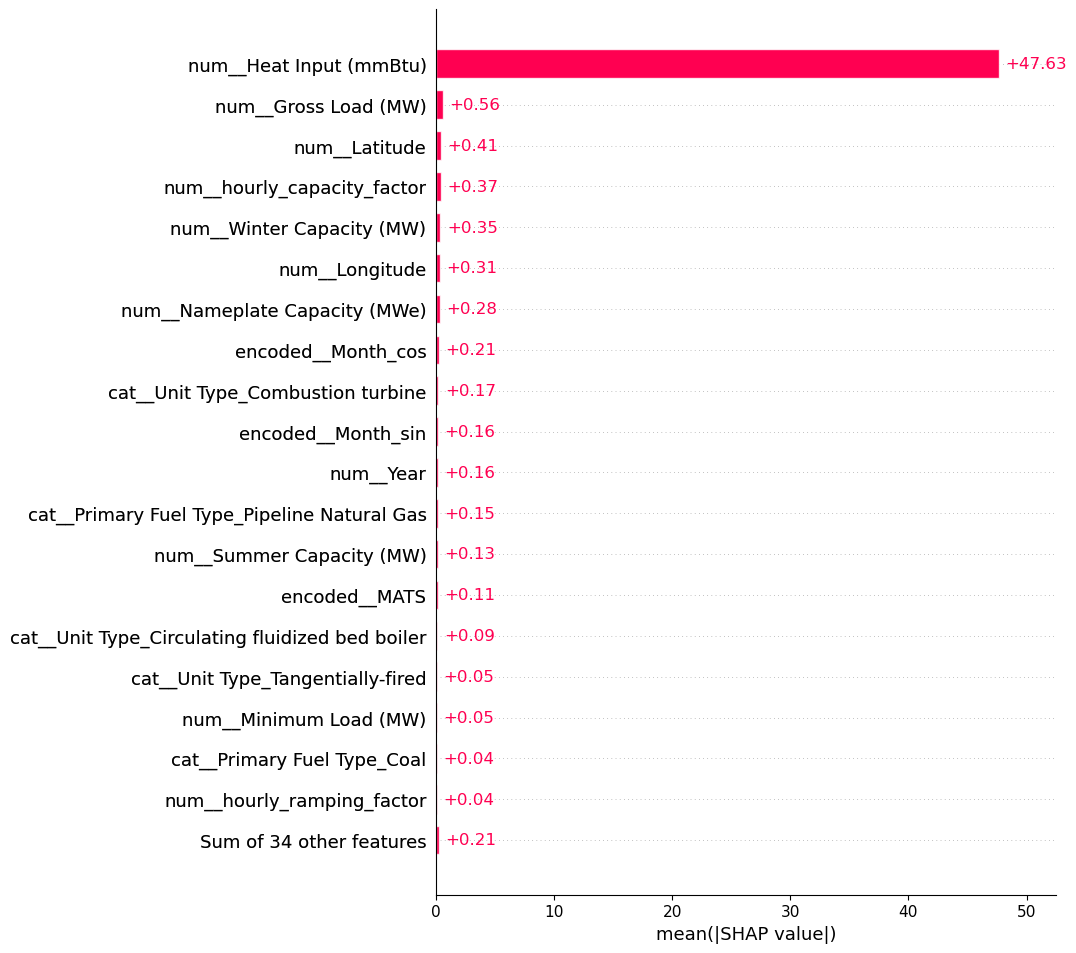

In [50]:
shap.plots.bar(shap_values, max_display=20)

In [53]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ]
}

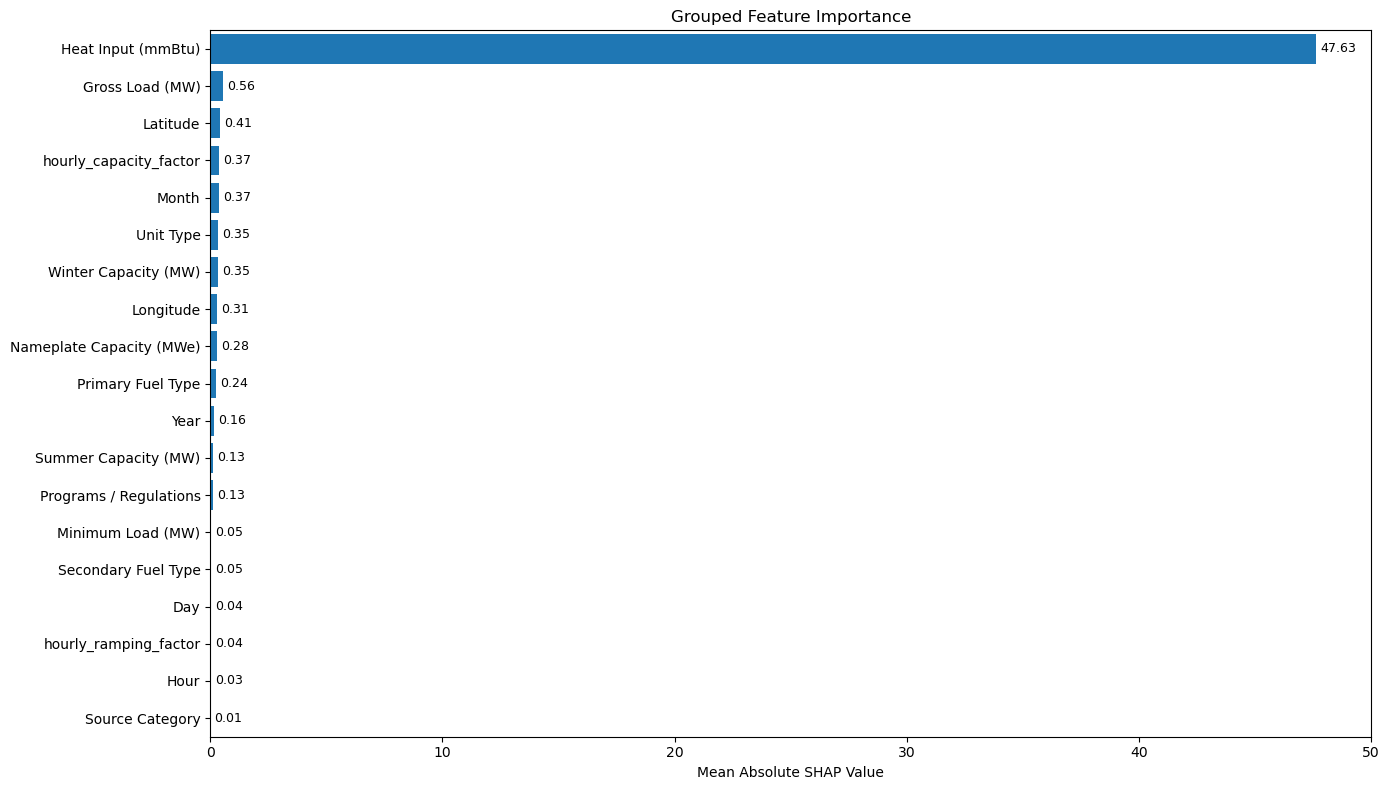

In [54]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


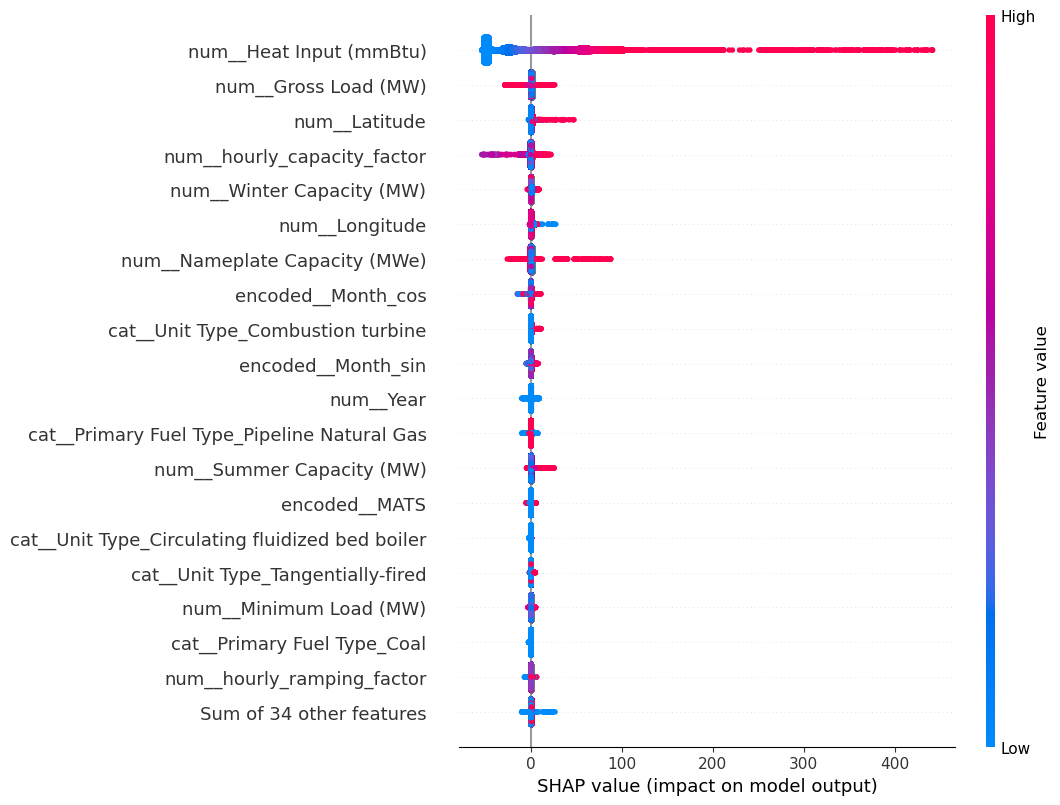

In [55]:
shap.plots.beeswarm(shap_values, max_display=20)

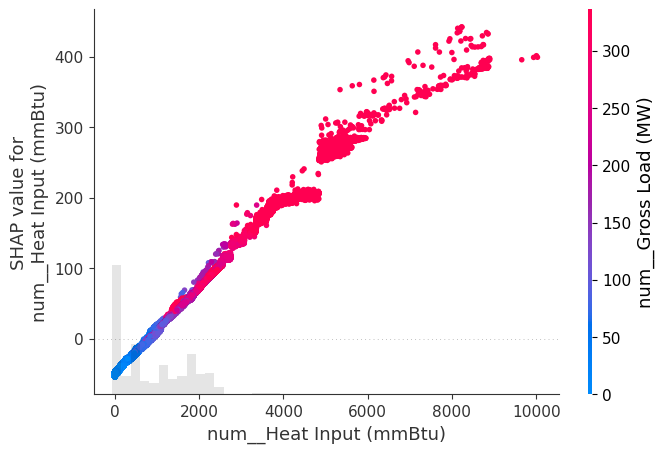

In [57]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])


<h5>With Lags</h5>

In [13]:
explainer = shap.TreeExplainer(xgb_default_model)

In [53]:
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed", dtype=campd_type_dict)

In [14]:
shap_values = explainer(X_test, approximate=True)

In [15]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_tx_with_lags_no_unmeasured.pkl")

['TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_tx_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_tx_with_lags_no_unmeasured.pkl")

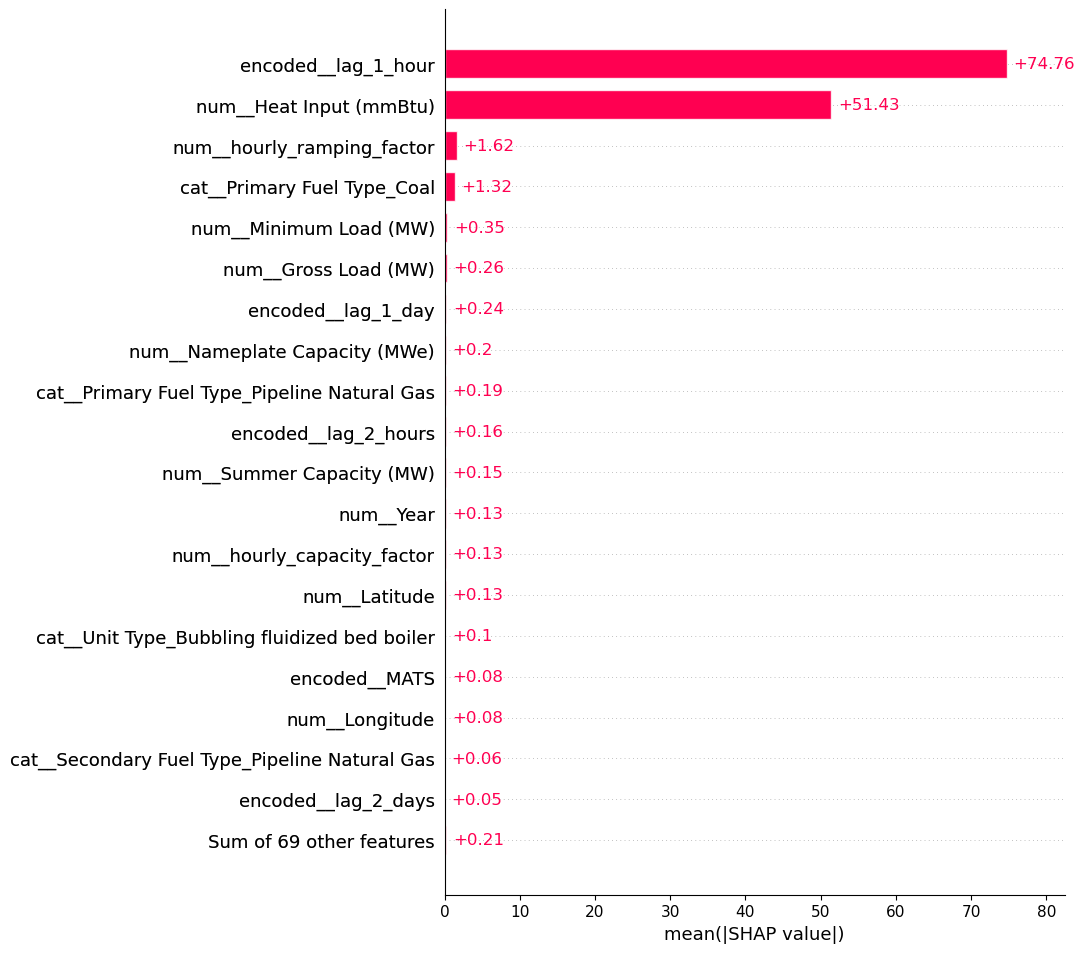

In [16]:
shap.plots.bar(shap_values, max_display=20)

In [39]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

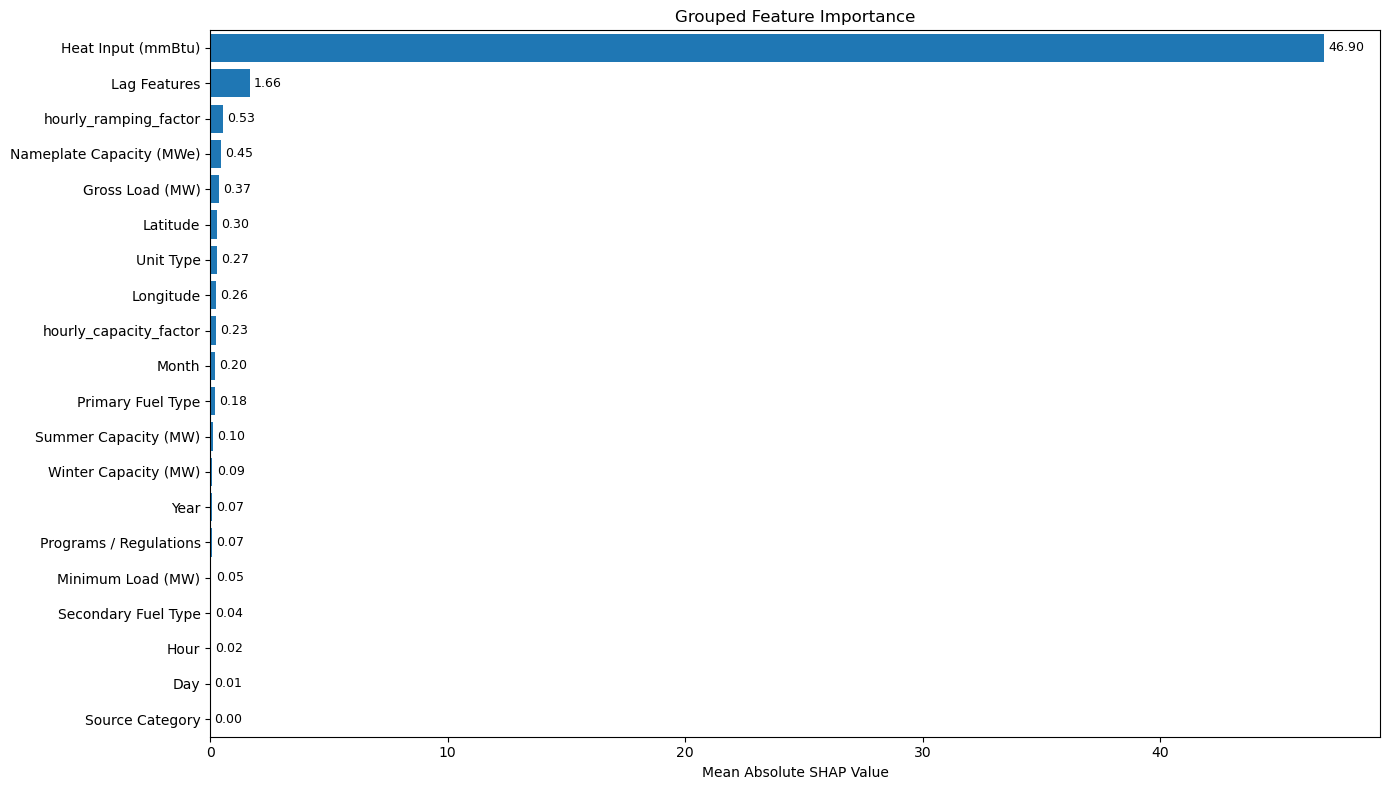

In [40]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


In [ ]:
shap.plots.waterfall(shap_values[0], max_display=20)

In [ ]:
# global visualizations

# shap.plots.bar(shap_values) # mean absolute value of each feature over all rows
# shap.plots.bar(shap_values.abs.max(0)) # gives max absolute values of features e. g. if features occur infrequently, but have significant effects
# shap.plots.beeswarm(shap_values) # beeswarm plot -> gives context on relationships of high and low feature values to SHAP values

# deal with clustering
# clustering = shap.utils.hclust(X_adult, y_adult)
# shap.plots.bar(shap_values, clustering=clustering)
# shap.plots.bar(shap_values, clustering=clustering, clustering_cutoff=1) # sets distance threshold for clusters, lower values will create smaller clusters

# shap.plots.scatter(shap_values, ylabel="SHAP value") # scatter plots between feature and shap values

<h4>Using HPO parameters</h4>

In [4]:
explainer = shap.TreeExplainer(xgb_hpo_model)

In [ ]:
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [6]:
shap_values = explainer(X_test, approximate=True) # need to approximate because otherwise it is to computationally expensive for the hpo model

In [ ]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_tx_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_tx_with_lags_no_unmeasured.pkl")

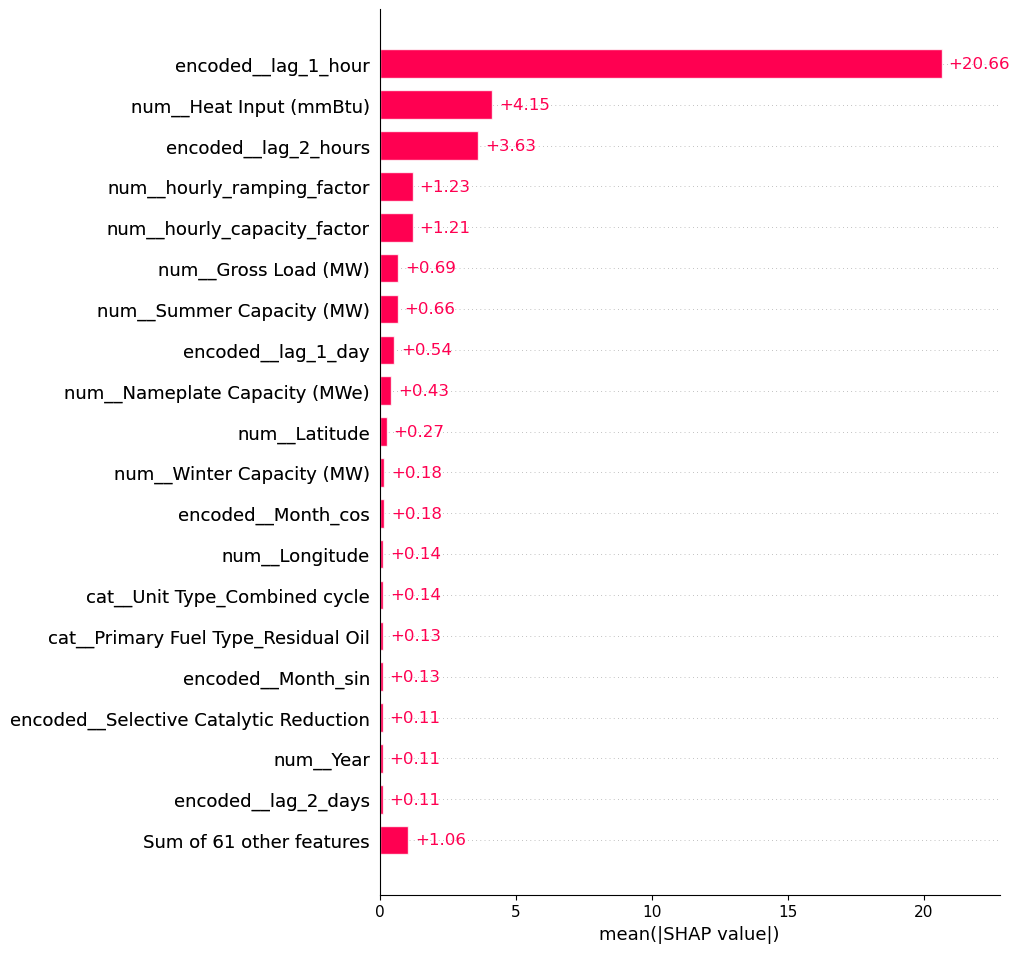

In [8]:
shap.plots.bar(shap_values, max_display=20)

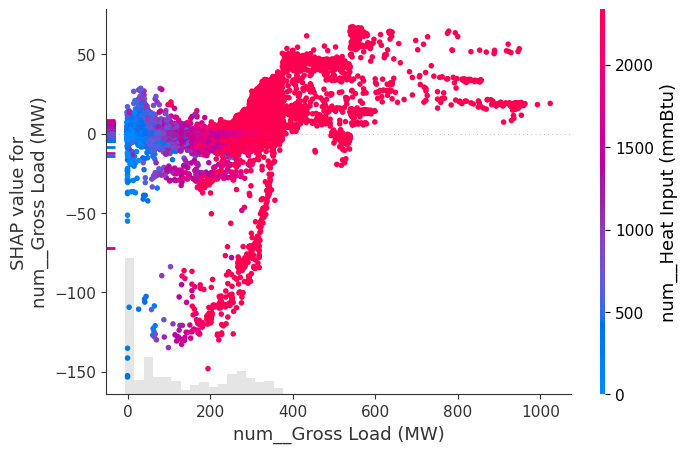

In [9]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


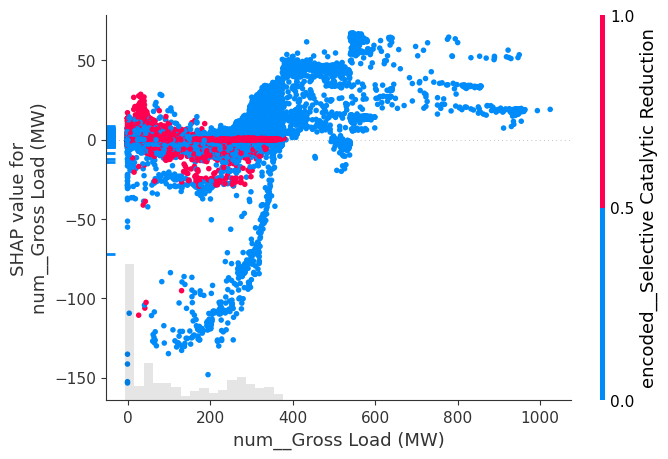

In [10]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"encoded__Selective Catalytic Reduction"])


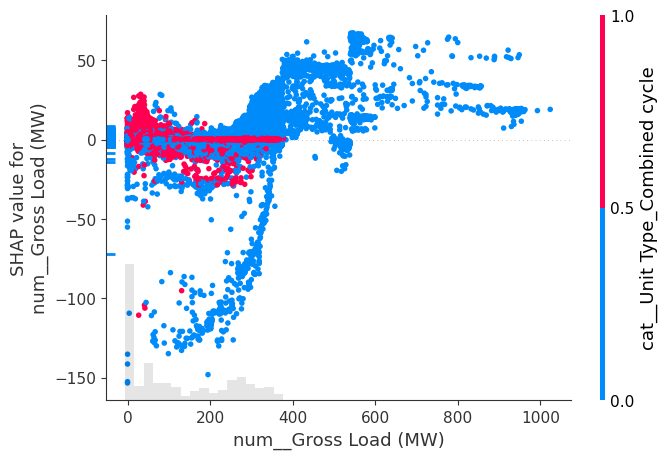

In [11]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"cat__Unit Type_Combined cycle"])  


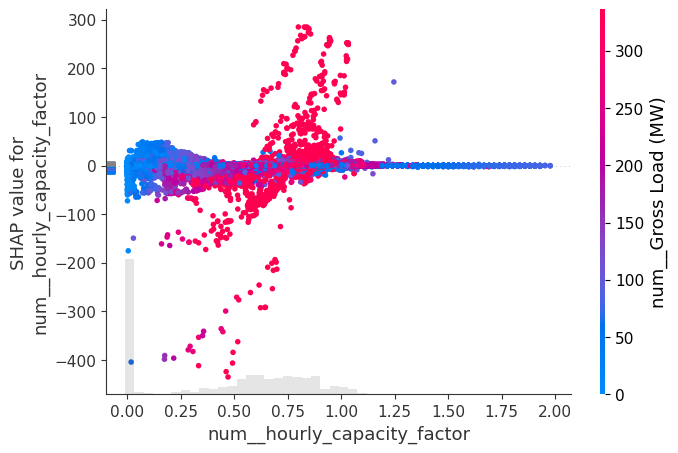

In [12]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"], color=shap_values[:,"num__Gross Load (MW)"])


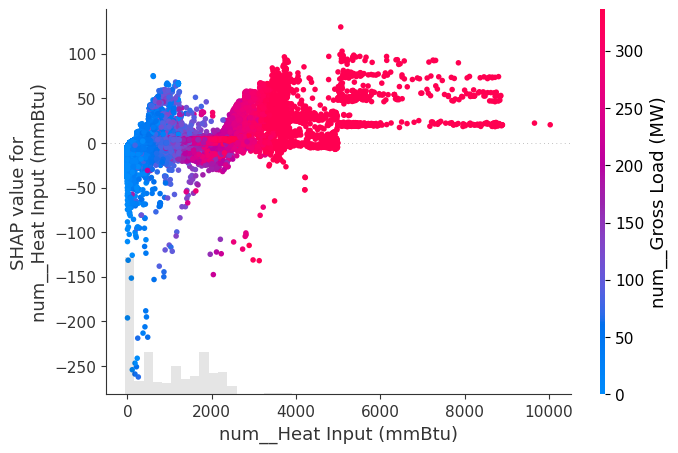

In [13]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])


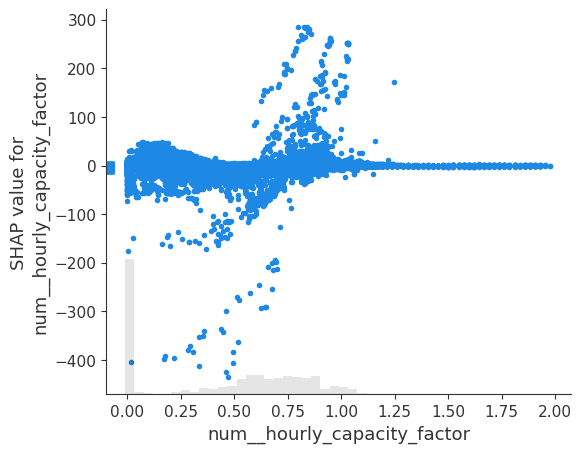

In [14]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"])#, color=shap_values[:,"encoded__Selective Catalytic Reduction"])


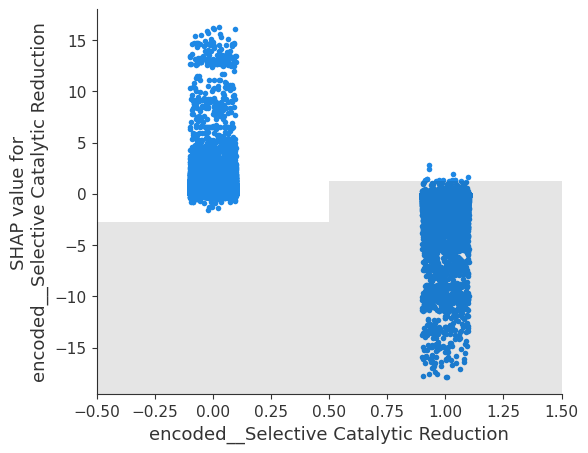

In [15]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"])


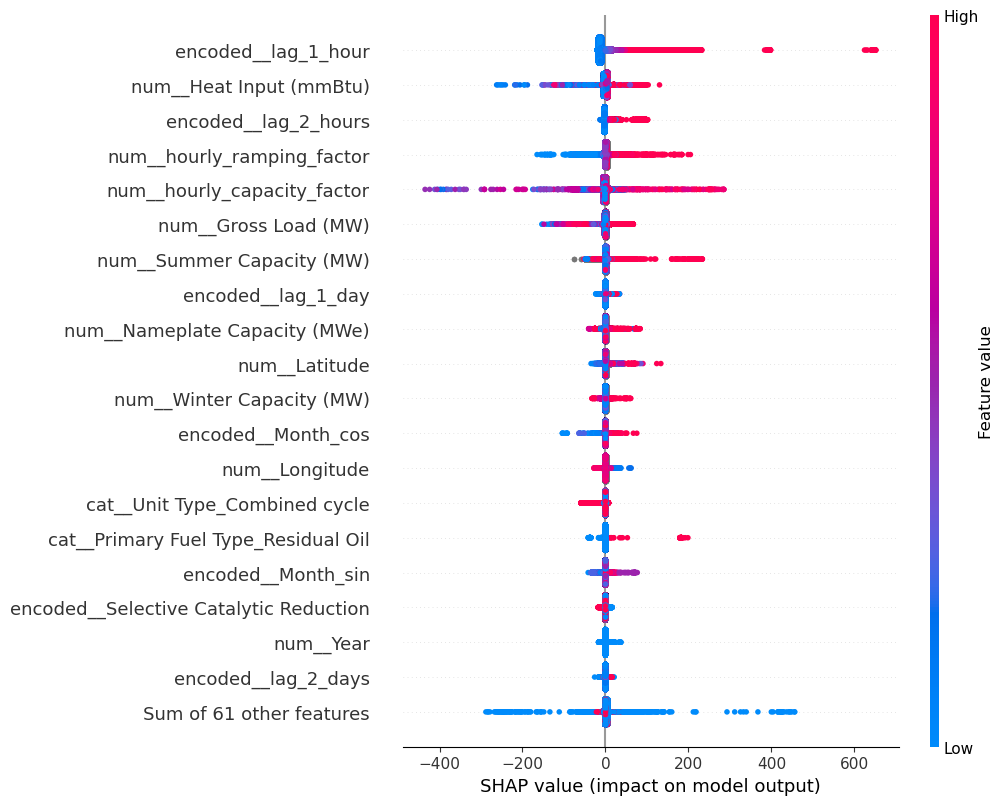

In [16]:
shap.plots.beeswarm(shap_values, max_display=20)


In [ ]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "CO2 Phase": [
        'cat__CO2 Phase_Early Election',
        'cat__CO2 Phase_Nothing',
        'cat__CO2 Phase_Phase 1 Group 1',
        'cat__CO2 Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
        'encoded__Ammonia Injection',
        'encoded__Combustion Modification/Fuel Reburning',
        'encoded__Dry Low CO2 Burners',
        'encoded__Low CO2 Burner Technology (Dry Bottom only)',
        'encoded__Low CO2 Burner Technology w/ Closed-coupled OFA',
        'encoded__Low CO2 Burner Technology w/ Closed-coupled/Separated OFA',
        'encoded__Low CO2 Burner Technology w/ Overfire Air',
        'encoded__Low CO2 Burner Technology w/ Separated OFA',
        'encoded__Nothing',
        'encoded__Other',
        'encoded__Overfire Air',
        'encoded__Selective Catalytic Reduction',
        'encoded__Selective Non-catalytic Reduction',
        'encoded__Steam Injection',
        'encoded__Water Injection',
        'encoded__Water Injection (Began Jul 01, 2022)'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

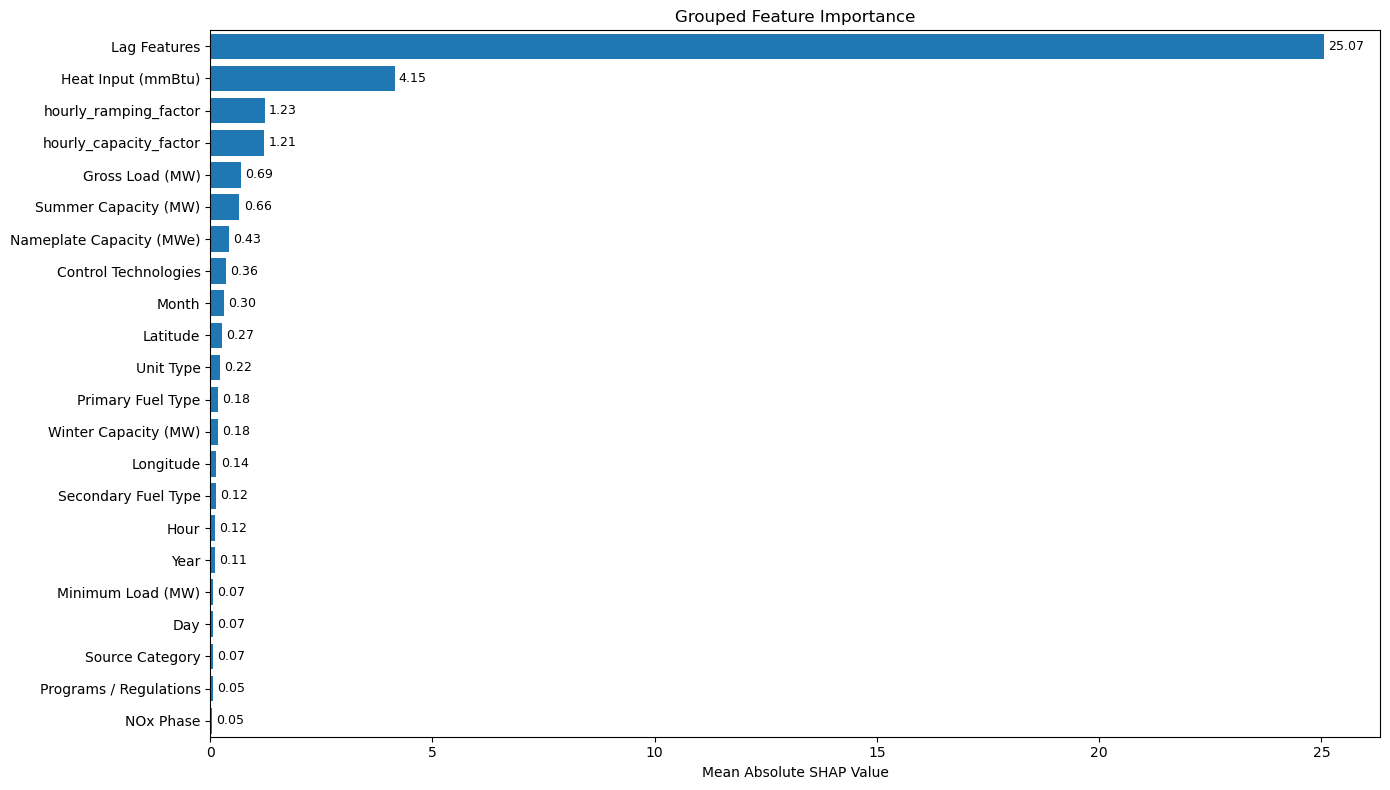

In [18]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


<h3>LIME</h3>